In [23]:
import datetime
import math

import geode
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

In [24]:
start_time = datetime.datetime(2026,10,1,0,0,tzinfo=datetime.UTC)
end_time = datetime.datetime(2026,10,2,0,0,tzinfo=datetime.UTC)
result_sfc = geode.get("temp_surface", start_time, end_time)
result_prof = geode.get("temp_upper_air", start_time, end_time)
print(result_sfc)
print(result_prof)

Getting data from file path: /scratch4/NCEPDEV/stmp/Cory.R.Martin/sep2026/geode_dev/geode_test_data/lake/temp_surface.icechunk
Getting data from file path: /scratch4/NCEPDEV/stmp/Cory.R.Martin/sep2026/geode_dev/geode_test_data/lake/temp_upper_air.icechunk


  2026-10-13T19:48:35.128541Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330

  2026-10-13T19:48:35.173700Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330



<xarray.DataTree>
Group: /
├── Group: /MetaData
│       Dimensions:                (Location: 1639)
│       Coordinates:
│         * Location               (Location) int64 13kB 0 2 3 4 ... 1700 1701 1702 1708
│       Data variables:
│           latitude               (Location) float64 13kB ...
│           longitude              (Location) float64 13kB ...
│           receiptTime            (Location) datetime64[ns] 13kB ...
│           stationElevation       (Location) float64 13kB ...
│           dateTime               (Location) datetime64[ns] 13kB 2026-10-01 ... 2026...
│           rawCode                (Location) object 13kB ...
│           stationIdentification  (Location) object 13kB ...
│           reportType             (Location) object 13kB ...
├── Group: /ObsValue
│       Dimensions:              (Location: 1639)
│       Coordinates:
│         * Location             (Location) int64 13kB 0 2 3 4 5 ... 1700 1701 1702 1708
│       Data variables:
│           dewPointTempera

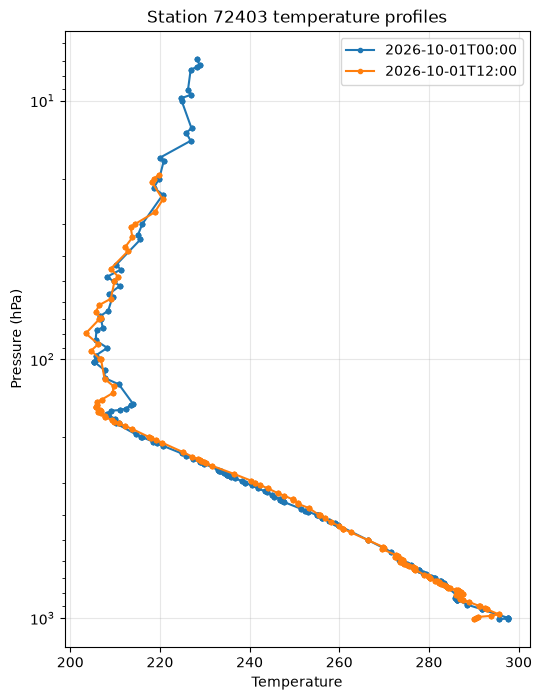

['2026-10-01T00:00:00.000000000' '2026-10-01T12:00:00.000000000']


In [25]:
# Select station 72403 and split into one profile per launch time.
prof_meta = result_prof["MetaData"].dataset
prof_obs = result_prof["ObsValue"].dataset
station_mask = prof_meta["stationIdentification"].values == "72403"
times = prof_meta["dateTime"].values[station_mask]
pres = prof_meta["pressure"].values[station_mask]
temp = prof_obs["temperature"].values[station_mask]

fig, ax = plt.subplots(figsize=(6, 8))
for t in np.unique(times):
    sel = (times == t) & np.isfinite(pres) & np.isfinite(temp)
    order = np.argsort(-pres[sel])
    ax.plot(temp[sel][order], pres[sel][order] / 100.0, marker="o", ms=3, label=str(t)[:16])
ax.set_yscale("log")
ax.invert_yaxis()
ax.set_xlabel("Temperature")
ax.set_ylabel("Pressure (hPa)")
ax.set_title("Station 72403 temperature profiles")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()
print(np.unique(times))

In [26]:
# Display all 72403 values from every group in the upper-air tree.
station_72403 = {
    group: result_prof[group].dataset.isel(Location=np.flatnonzero(station_mask))
    for group in result_prof.children
}
display(station_72403)

{'MetaData': <xarray.Dataset> Size: 153kB
 Dimensions:                (Location: 1598)
 Coordinates:
   * Location               (Location) int64 13kB 11299 11300 ... 137135 137136
 Data variables:
     stationElevation       (Location) float64 13kB ...
     height                 (Location) float64 13kB ...
     latitude               (Location) float64 13kB ...
     pressure               (Location) float64 13kB 1e+05 9.25e+04 ... 1.05e+04
     receiptTime            (Location) datetime64[ns] 13kB ...
     longitude              (Location) float64 13kB ...
     reportType             (Location) object 13kB ...
     rawCode                (Location) object 13kB ...
     dateTime               (Location) datetime64[ns] 13kB 2026-10-01 ... 2026...
     stationIdentification  (Location) StringDType() 26kB '72403' ... '72403',
 'ObsValue': <xarray.Dataset> Size: 64kB
 Dimensions:              (Location: 1598)
 Coordinates:
   * Location             (Location) int64 13kB 11299 11300 ... 13

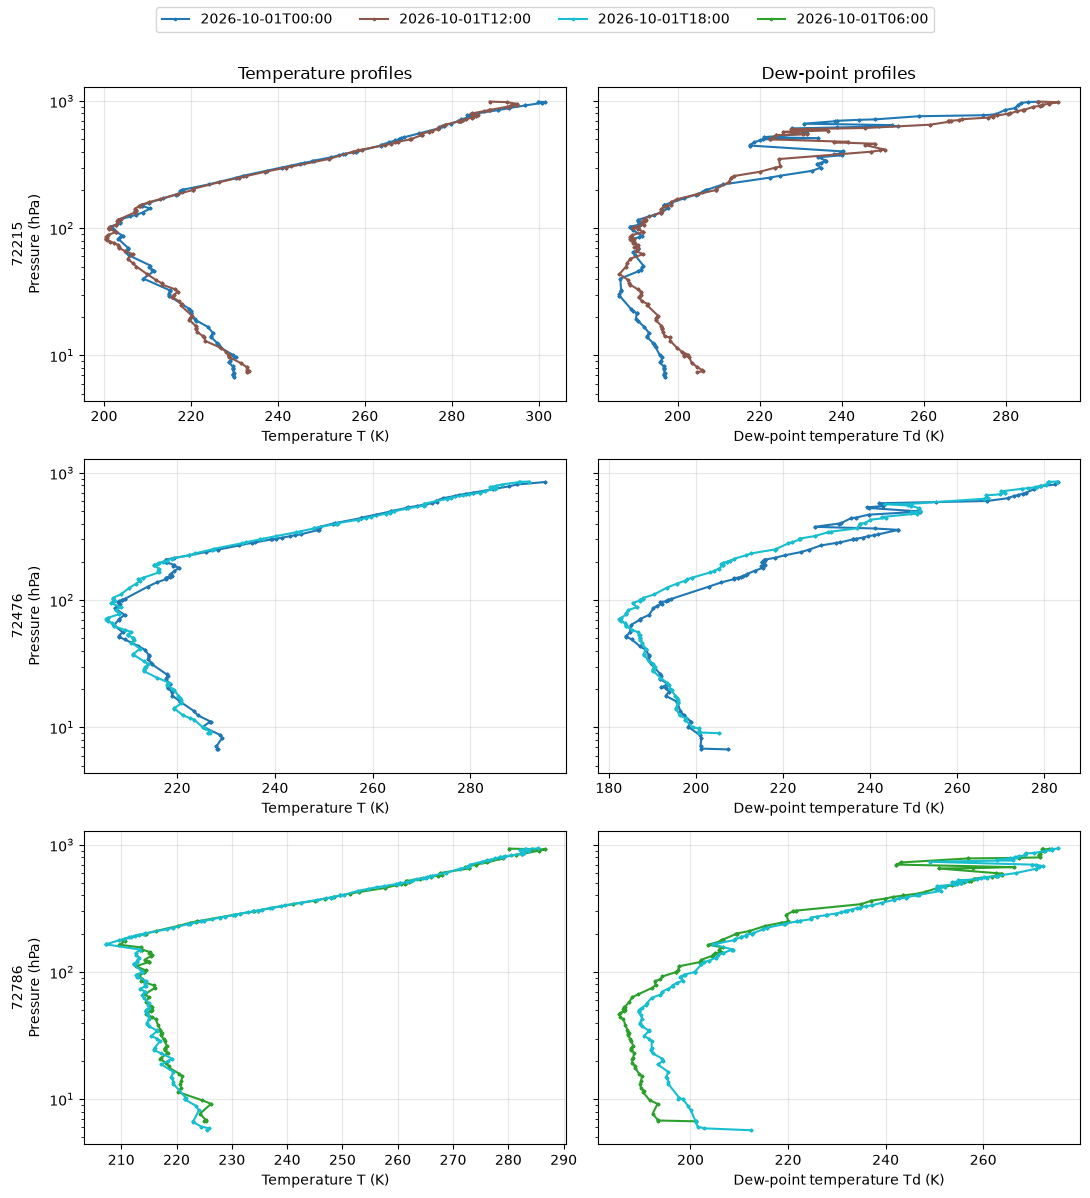

In [27]:
prof_meta = result_prof["MetaData"].dataset
prof_obs = result_prof["ObsValue"].dataset
all_station_ids = prof_meta["stationIdentification"].values
pressure_all = prof_meta["pressure"].values
temperature_all = prof_obs["temperature"].values
dewpoint_all = prof_obs["dewPointTemperature"].values
time_all = prof_meta["dateTime"].values
report_type_all = prof_meta["reportType"].values
raw_codes = prof_meta["rawCode"].values if "rawCode" in prof_meta else None

stations_to_check = ["72215", "72476", "72786"]
launch_times_all = np.unique(time_all)
launch_colors = {
    launch_time: plt.cm.tab10(i % 10)
    for i, launch_time in enumerate(launch_times_all)
}
fig, axes = plt.subplots(3, 2, figsize=(11, 12), sharey=True, squeeze=False)
for row, station_id in enumerate(stations_to_check):
    station_sel = all_station_ids == station_id
    for launch_time in np.unique(time_all[station_sel]):
        sel = station_sel & (time_all == launch_time) & np.isfinite(pressure_all) & (pressure_all > 0)
        order = np.argsort(-pressure_all[sel])
        p_hpa = pressure_all[sel][order] / 100.0
        temp_profile = temperature_all[sel][order]
        dewpoint_profile = dewpoint_all[sel][order]
        label = str(launch_time)[:16]
        color = launch_colors[launch_time]
        t_valid = np.isfinite(temp_profile)
        td_valid = np.isfinite(dewpoint_profile)
        axes[row, 0].plot(temp_profile[t_valid], p_hpa[t_valid], ".-", ms=3, color=color, label=label)
        axes[row, 1].plot(dewpoint_profile[td_valid], p_hpa[td_valid], ".-", ms=3, color=color, label=label)
    for ax in axes[row]:
        ax.set_yscale("log")
        ax.invert_yaxis()
        ax.grid(True, alpha=0.3)
    axes[row, 0].set_ylabel(f"{station_id}\nPressure (hPa)")
    axes[row, 0].set_xlabel("Temperature T (K)")
    axes[row, 1].set_xlabel("Dew-point temperature Td (K)")
axes[0, 0].set_title("Temperature profiles")
axes[0, 1].set_title("Dew-point profiles")
legend_handles = {}
for ax in axes.flat:
    for line in ax.get_lines():
        legend_handles.setdefault(line.get_label(), line)
fig.legend(legend_handles.values(), legend_handles.keys(), loc="upper center", ncol=max(1, len(legend_handles)))
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

2026-10-01T00:00 levels with dew point: 553 of 834 | dewpt > temp: 0
2026-10-01T12:00 levels with dew point: 548 of 764 | dewpt > temp: 0


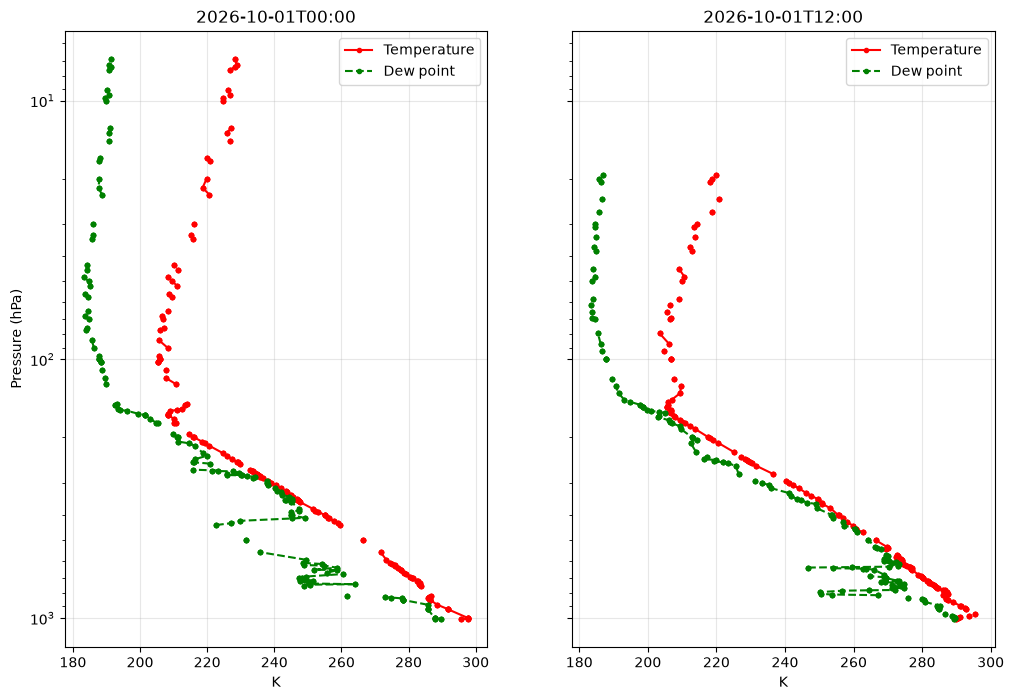

In [28]:
# Temperature (solid) and dew point (dashed) per launch time; dew point must not exceed temperature.
dewpt = prof_obs["dewPointTemperature"].values[station_mask]

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
for ax, t in zip(axes, np.unique(times)):
    sel = (times == t) & np.isfinite(pres)
    order = np.argsort(-pres[sel])
    p = pres[sel][order] / 100.0
    ax.plot(temp[sel][order], p, "r-o", ms=3, label="Temperature")
    ax.plot(dewpt[sel][order], p, "g--o", ms=3, label="Dew point")
    ax.set_yscale("log")
    ax.set_xlabel("K")
    ax.set_title(str(t)[:16])
    ax.grid(True, alpha=0.3)
    ax.legend()
    both = sel & np.isfinite(temp) & np.isfinite(dewpt)
    print(str(t)[:16], "levels with dew point:", both.sum(), "of", sel.sum(),
          "| dewpt > temp:", (dewpt[both] > temp[both]).sum())
axes[0].invert_yaxis()
axes[0].set_ylabel("Pressure (hPa)")
plt.show()

2026-10-01T00:00 levels with wind: 402 | max speed (m/s): 42.698852
2026-10-01T12:00 levels with wind: 316 | max speed (m/s): 29.837752000000002


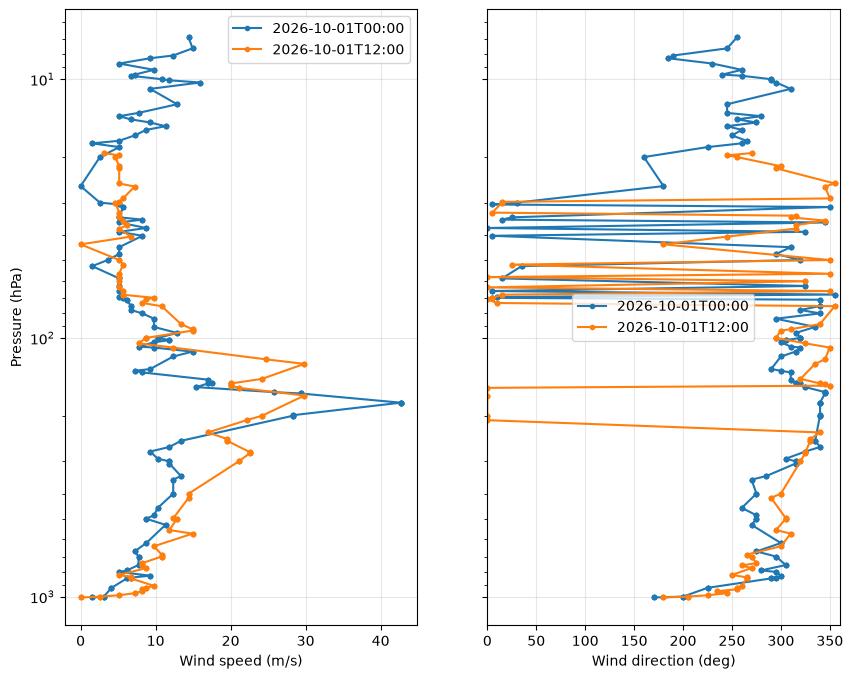

In [29]:
# Wind speed (m/s) and direction (deg) per launch, derived from u/v components.
u = prof_obs["windEastward"].values[station_mask]
v = prof_obs["windNorthward"].values[station_mask]
speed = np.hypot(u, v)
direction = (np.degrees(np.arctan2(-u, -v)) + 360.0) % 360.0

fig, axes = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
for t in np.unique(times):
    sel = (times == t) & np.isfinite(pres) & np.isfinite(speed)
    order = np.argsort(-pres[sel])
    p = pres[sel][order] / 100.0
    axes[0].plot(speed[sel][order], p, "-o", ms=3, label=str(t)[:16])
    axes[1].plot(direction[sel][order], p, "-o", ms=3, label=str(t)[:16])
    print(str(t)[:16], "levels with wind:", sel.sum(), "| max speed (m/s):", np.nanmax(speed[sel]))
axes[0].set_yscale("log")
axes[0].invert_yaxis()
axes[0].set_xlabel("Wind speed (m/s)")
axes[0].set_ylabel("Pressure (hPa)")
axes[1].set_xlabel("Wind direction (deg)")
axes[1].set_xlim(0, 360)
for a in axes:
    a.grid(True, alpha=0.3)
    a.legend()
plt.show()

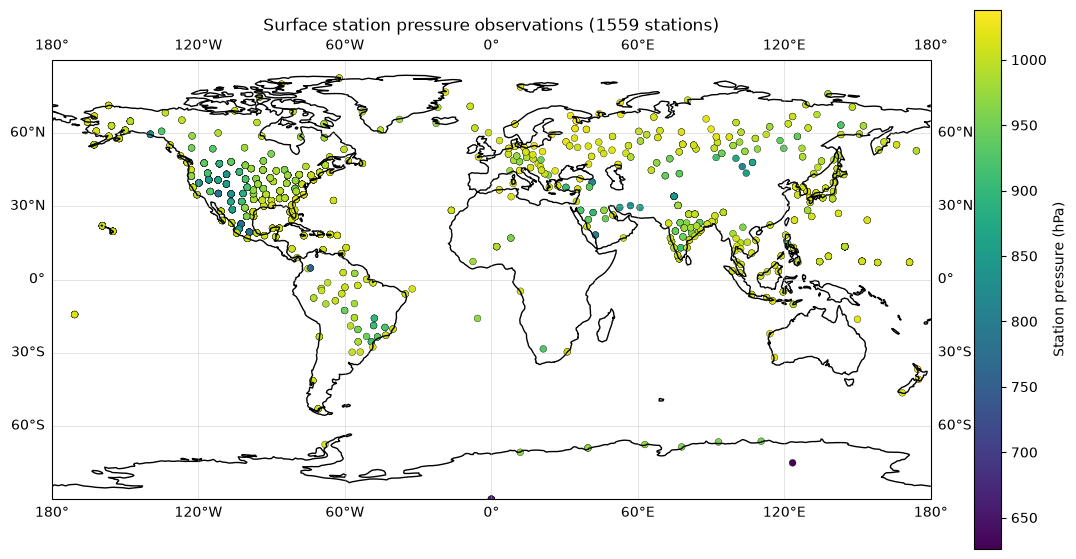

In [30]:
# Plot all surface station-pressure observations (pressure is stored in Pa).
surface_metadata = result_sfc["MetaData"].dataset
surface_observations = result_sfc["ObsValue"].dataset
latitude = surface_metadata["latitude"].values
longitude = surface_metadata["longitude"].values
station_pressure = surface_observations["stationPressure"].values
valid = (
    np.isfinite(latitude)
    & np.isfinite(longitude)
    & np.isfinite(station_pressure)
)

fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_global()
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
points = ax.scatter(
    longitude[valid],
    latitude[valid],
    c=station_pressure[valid] / 100.0,
    cmap="viridis",
    s=24,
    edgecolors="black",
    linewidths=0.25,
    transform=ccrs.PlateCarree(),
)
colorbar = plt.colorbar(points, ax=ax, orientation="vertical", pad=0.04)
colorbar.set_label("Station pressure (hPa)")
ax.set_title(f"Surface station pressure observations ({valid.sum()} stations)")
plt.show()